# 03 · MapBiomas Fuego — dónde y cuándo se quemó

**Qué hace:** localiza el producto de área quemada de MapBiomas Perú, cuantifica cuánto ardió en la
provincia por mes y por año, y construye las **máscaras anuales de quema alineadas a nuestra ventana
de compuesto**.

**Qué NO hace:** no clasifica nada ni decide si un cambio fue quema. Eso es el notebook 07. Aquí solo
se prepara el dato para que llegue utilizable.

### Qué consume

| Entrada | De dónde |
|---|---|
| Área de estudio | Asset `cusco_01_aoi` (notebook 01) |
| Máscara de pajonal | Asset `cusco_02_mascara` (notebook 02) |
| Producto de fuego | MapBiomas Perú, colección de fuego (se localiza en la sección 2) |

### Qué produce

| Salida | La consume |
|---|---|
| `outputs/03_referencia_fuego/area_quemada_mensual.csv` | Documentación e informe |
| `outputs/03_referencia_fuego/area_quemada_anual.csv` | Documentación e informe |
| Asset `cusco_03_quema_aparicion` | **Notebook 07**: una banda por año, con la quema ya desfasada |

---

## Por qué este notebook existe

Una quema produce **la misma firma espectral que la degradación**: cae la vegetación, sube el suelo
expuesto, baja la humedad. LandTrendr detecta que un píxel perdió cobertura en tal año, pero no
puede decir si fue por sobrepastoreo o porque ardió. Sin el dato de fuego, las dos cosas entran
juntas en la cifra del entregable.

Y para el cliente no son lo mismo: la degradación por pastoreo se atiende con manejo ganadero, un
incendio con prevención y respuesta. Reportar una como la otra a un gobierno regional es un error de
fondo.

**No es un confusor menor en esta provincia.** La revisión preliminar daba unos 60 km² quemados
acumulados entre 2013 y 2024, con picos anuales de 8 a 12 km², sobre 258 km² de pajonal. Si eso se
cuela en el indicador, la cifra queda inflada.

---

## El problema de calendario, que es lo importante de este notebook

Nuestro compuesto anual se construye con escenas de **junio a agosto**. Los incendios de la provincia
se concentran entre **septiembre y noviembre**. Las dos ventanas no coinciden, y eso tiene una
consecuencia que invalida el cruce ingenuo por año:

| Mes del incendio | Dónde aparece la cicatriz |
|---|---|
| **≤ agosto** | Compuesto del año *t*. El fuego ocurrió dentro o antes de la ventana |
| **≥ septiembre** | Compuesto del año ***t+1***. La ventana de ese año ya había cerrado |

Un incendio de septiembre de 2021 **no se ve** en el compuesto de 2021: para cuando Landsat vuelve a
mirar en junio de 2022, han pasado nueve meses. Así que LandTrendr detectará el quiebre en 2022, un
año después del fuego.

Y los tres incendios más grandes del periodo —noviembre 2020, octubre 2021, septiembre 2019— son
todos posteriores a la ventana. **Si se cruza por año a secas, se escapan justo los tres eventos que
más importan.**

Por eso este notebook no entrega "área quemada por año" y ya. Entrega la quema indexada por **año de
aparición**: el año del compuesto donde la cicatriz va a ser visible. El notebook 07 recibe el dato
ya alineado y no tiene que razonar sobre calendarios.

**Orden del proyecto:** 01 área → 02 cobertura → **03 fuego** → 04 serie anual → 05 detección →
06 control → 07 tipo de cambio → 08 clima → 09 validación → 10 entregables.

## 1 · Configuración

In [12]:
from pathlib import Path
import re

import ee
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

GEE_PROJECT = "viirs-peru"

# Assets de los notebooks anteriores
ASSET_AOI = f"projects/{GEE_PROJECT}/assets/cusco_01_aoi"
ASSET_MASCARA = f"projects/{GEE_PROJECT}/assets/cusco_02_mascara"
ASSET_QUEMA = f"projects/{GEE_PROJECT}/assets/cusco_03_quema_aparicion"

# Carpeta pública de MapBiomas Perú. El producto de fuego se localiza en la sección 2:
# no se escribe su ruta a mano porque la colección de fuego es distinta a la de cobertura
# y su nombre puede cambiar entre versiones.
CARPETA_MB = "projects/mapbiomas-public/assets/peru"

ANIO_INI, ANIO_FIN = 2013, 2025
ANIOS = list(range(ANIO_INI, ANIO_FIN + 1))

# La ventana del compuesto anual, que define el desfase (ver encabezado)
MES_CIERRE_VENTANA = 8      # agosto. Quemas de mes <= 8 se ven en el año t; >= 9 en t+1

ESCALA = 30
ESCALA_STATS = 60           # las áreas no necesitan 30 m
GRID_CRS = "EPSG:32719"
TILE_SCALE = 4


def buscar_raiz(inicio=None):
    """Sube por las carpetas hasta encontrar la raíz del proyecto."""
    inicio = Path(inicio or Path.cwd()).resolve()
    for carpeta in [inicio, *inicio.parents]:
        if (carpeta / "data" / "raw" / "Provincia" / "PROVINCIA.gpkg").is_file():
            return carpeta
    raise FileNotFoundError("No encuentro data/raw/Provincia/PROVINCIA.gpkg desde esta ubicación.")


def iniciar_gee(proyecto=GEE_PROJECT):
    try:
        ee.Initialize(project=proyecto)
    except Exception:
        ee.Authenticate()
        ee.Initialize(project=proyecto)


def con_reintentos(fn, intentos=6, espera=5):
    """Reintenta ante errores transitorios de Earth Engine."""
    import time
    for i in range(intentos):
        try:
            return fn()
        except Exception as e:
            msg = repr(e)
            if not any(t in msg for t in ["concurrent", "Too many", "Timed out", "timed out",
                                          "quota", "503", "500", "Connection"]) or i == intentos - 1:
                raise
            pausa = espera * (i + 1)
            print(f"\n    reintento {i + 1} en {pausa}s · {msg[:90]}")
            time.sleep(pausa)


def evaluar_serie(objetos, etiquetas=None, pausa=0.4):
    """getInfo() uno por uno: varias reducciones a la vez disparan
    'Too many concurrent aggregations'."""
    import time
    etiquetas = etiquetas or [str(i) for i in range(len(objetos))]
    salida = []
    for i, (obj, et) in enumerate(zip(objetos, etiquetas), 1):
        print(f"  [{i}/{len(objetos)}] {et}", end="  ", flush=True)
        salida.append(con_reintentos(lambda o=obj: o.getInfo()))
        print("ok", flush=True)
        if pausa and i < len(objetos):
            time.sleep(pausa)
    return salida


iniciar_gee()
RAIZ = buscar_raiz()
SALIDA = RAIZ / "outputs" / "03_referencia_fuego"

print("Raíz del proyecto:", RAIZ)
print("Periodo          :", ANIOS[0], "-", ANIOS[-1])
print("Cierre de ventana:", f"mes {MES_CIERRE_VENTANA} (agosto)")
CONFIG_LISTA = True

Raíz del proyecto: F:\Cobertura de suelo
Periodo          : 2013 - 2025
Cierre de ventana: mes 8 (agosto)


## 2 · Localizar el producto de fuego

La ruta no se escribe a mano. Se lista la carpeta pública de MapBiomas Perú y se busca el asset
cuyo nombre contenga `fire` y `burned`, porque:

- La colección de fuego es **independiente** de la de cobertura: otra numeración, otra versión, otra
  estructura de bandas.
- El nombre cambia entre versiones, y una ruta fija escrita a mano se rompe en silencio cuando
  MapBiomas publica una colección nueva.

La celda imprime todo lo que encuentra antes de elegir, para que se vea con qué se está trabajando.

In [13]:
def listar_recursivo(carpeta, nivel=0, max_nivel=3):
    """Lista assets de GEE recursivamente, entrando solo en carpetas."""
    salida, token = [], None
    while True:
        params = {"parent": carpeta}
        if token:
            params["pageToken"] = token
        try:
            resp = con_reintentos(lambda: ee.data.listAssets(params))
        except Exception as e:
            print(f"  no pude listar {carpeta}: {repr(e)[:120]}")
            return salida
        for a in resp.get("assets", []):
            salida.append({"id": a["id"], "tipo": a["type"], "nivel": nivel})
            if a["type"] == "FOLDER" and nivel < max_nivel:
                salida += listar_recursivo(a["id"], nivel + 1, max_nivel)
        token = resp.get("nextPageToken")
        if not token:
            return salida


print(f"Listando {CARPETA_MB} ...")
assets = listar_recursivo(CARPETA_MB)
print(f"{len(assets)} assets encontrados\n")

candidatos = [a for a in assets
              if "fire" in a["id"].lower() and a["tipo"] in ("IMAGE", "IMAGE_COLLECTION")]

print("Assets de fuego disponibles:")
for a in candidatos:
    print(f"  [{a['tipo']:16s}] {a['id'].split('/')[-1]}")

# Preferimos el producto MENSUAL: es el que permite resolver el desfase por mes.
mensuales = [a for a in candidatos if "monthly" in a["id"].lower()]
anuales = [a for a in candidatos if "annual" in a["id"].lower() or "year" in a["id"].lower()]

if mensuales:
    ASSET_FUEGO = sorted(mensuales, key=lambda a: a["id"])[-1]["id"]   # la versión más alta
    TIPO_FUEGO = [a for a in mensuales if a["id"] == ASSET_FUEGO][0]["tipo"]
    MENSUAL = True
elif anuales:
    ASSET_FUEGO = sorted(anuales, key=lambda a: a["id"])[-1]["id"]
    TIPO_FUEGO = [a for a in anuales if a["id"] == ASSET_FUEGO][0]["tipo"]
    MENSUAL = False
    print("\n⚠ No hay producto mensual: solo anual. El desfase por mes NO se podrá resolver")
    print("  y habrá que cruzar con tolerancia de ±1 año en el notebook 07.")
elif candidatos:
    ASSET_FUEGO, TIPO_FUEGO, MENSUAL = candidatos[0]["id"], candidatos[0]["tipo"], False
else:
    raise RuntimeError(
        f"No encontré ningún producto de fuego bajo {CARPETA_MB}. "
        "Revisa el listado de arriba y fija ASSET_FUEGO a mano.")

print(f"\nElegido : {ASSET_FUEGO}")
print(f"Tipo    : {TIPO_FUEGO}")
print(f"Mensual : {MENSUAL}")

Listando projects/mapbiomas-public/assets/peru ...
  no pude listar projects/mapbiomas-public/assets/peru/collection4: EEException("Permission 'earthengine.assets.get' denied on resource 'projects/mapbiomas-public/assets/peru/collection4' 
  no pude listar projects/mapbiomas-public/assets/peru/fire/monitor: EEException("Permission 'earthengine.assets.get' denied on resource 'projects/mapbiomas-public/assets/peru/fire/monitor'
  no pude listar projects/mapbiomas-public/assets/peru/lulc: EEException("Permission 'earthengine.assets.get' denied on resource 'projects/mapbiomas-public/assets/peru/lulc' (or it 
  no pude listar projects/mapbiomas-public/assets/peru/water/collection4: EEException("Permission 'earthengine.assets.get' denied on resource 'projects/mapbiomas-public/assets/peru/water/collect
107 assets encontrados

Assets de fuego disponibles:
  [IMAGE           ] mapbiomas_peru_fire_collection1_accumulated_burned_coverage_v1
  [IMAGE           ] mapbiomas_peru_fire_collection1_acc

## 3 · Verificar la estructura del producto

No se asume nada sobre cómo está organizado: se imprime y se comprueba.

Lo que hay que averiguar son dos cosas, y de ellas depende todo el resto:

1. **Cómo se indexan los años.** Igual que la cobertura usa `classification_YYYY`, el producto de
   fuego tendrá su propio patrón. Se detecta con una expresión regular sobre los nombres de banda.
2. **Qué significa el valor del píxel.** La hipótesis de trabajo es que en el producto mensual
   **el valor codifica el mes de la quema** (1 a 12, con 0 o enmascarado donde no ardió). El nombre
   `monthly_burned` apunta en esa dirección y una revisión preliminar del proyecto lo daba por
   "consistente", pero **sin confirmar contra la documentación de MapBiomas Fuego**.

La celda verifica la hipótesis: si los valores presentes caen dentro de 0–12, se sostiene. Si
aparecen valores fuera de ese rango, el valor significa otra cosa y hay que leer la documentación
antes de seguir.

**Esta es la advertencia que debe acompañar a cualquier cifra mensual de este notebook:** los
totales anuales son más confiables que la asignación por mes, porque el total no depende de cómo se
interprete el valor y la asignación mensual sí.

In [14]:
# Área de estudio y máscara, desde los assets de los notebooks previos
try:
    aoi = ee.FeatureCollection(ASSET_AOI).geometry()
    print("AOI leído del asset", ASSET_AOI.split("/")[-1])
except Exception as e:
    print("No pude leer el AOI del asset:", repr(e)[:120])
    print("→ Reconstruyéndolo desde el GeoPackage (ejecuta el notebook 01 y su exportación)")
    _p = gpd.read_file(RAIZ / "data" / "raw" / "Provincia" / "PROVINCIA.gpkg")
    _p = _p[(_p["ccdd"] == "08") & (_p["ccpp"] == "01")]
    aoi = ee.Geometry(_p.geometry.iloc[0].simplify(0.0001, preserve_topology=True).__geo_interface__)

try:
    mascaras = ee.Image(ASSET_MASCARA)
    pastizal = mascaras.select("pastizal").selfMask()
    print("Máscara de pajonal leída del asset", ASSET_MASCARA.split("/")[-1])
    HAY_MASCARA = True
except Exception as e:
    print("No pude leer la máscara del asset:", repr(e)[:120])
    print("→ La sección 6 (cruce con pajonal) se saltará. Ejecuta el notebook 02 y su exportación.")
    HAY_MASCARA = False

# --- Estructura del producto de fuego ---------------------------------------
if TIPO_FUEGO == "IMAGE":
    fuego = ee.Image(ASSET_FUEGO)
    bandas = con_reintentos(lambda: fuego.bandNames().getInfo())
else:
    col_fuego = ee.ImageCollection(ASSET_FUEGO)
    fuego = col_fuego.mosaic()
    bandas = con_reintentos(lambda: ee.Image(col_fuego.first()).bandNames().getInfo())
    print("Imágenes en la colección:", con_reintentos(lambda: col_fuego.size().getInfo()))

print(f"\nBandas ({len(bandas)}):", bandas[:8], "..." if len(bandas) > 8 else "")

# Detectar el patrón de año en los nombres de banda
anios_banda = {}
for b in bandas:
    m = re.search(r"(19|20)\d{2}", b)
    if m:
        anios_banda[int(m.group(0))] = b

if anios_banda:
    disp = sorted(anios_banda)
    print(f"Años detectados en las bandas: {disp[0]}–{disp[-1]} ({len(disp)} años)")
    patron = anios_banda[disp[0]].replace(str(disp[0]), "YYYY")
    print("Patrón de nombre:", patron)
else:
    print("⚠ No detecté años en los nombres de banda. Revisa la lista de arriba.")
    disp = []

faltan = [a for a in ANIOS if a not in anios_banda]
if faltan:
    print(f"⚠ Años del periodo sin banda de fuego: {faltan}")
    print("  Esos años se tratarán como 'sin quema registrada', que NO es lo mismo que 'no ardió'.")

AOI leído del asset cusco_01_aoi
Máscara de pajonal leída del asset cusco_02_mascara

Bandas (36): ['burned_monthly_1990', 'burned_monthly_1991', 'burned_monthly_1992', 'burned_monthly_1993', 'burned_monthly_1994', 'burned_monthly_1995', 'burned_monthly_1996', 'burned_monthly_1997'] ...
Años detectados en las bandas: 1990–2025 (36 años)
Patrón de nombre: burned_monthly_YYYY


In [15]:
# ¿El valor del píxel es el mes? Verificación de la hipótesis.
anio_prueba = next((a for a in [2020, 2021, 2019] if a in anios_banda), disp[-1] if disp else None)

if anio_prueba:
    banda_prueba = fuego.select(anios_banda[anio_prueba])
    hist = con_reintentos(lambda: banda_prueba.reduceRegion(
        ee.Reducer.frequencyHistogram(), aoi, ESCALA_STATS,
        maxPixels=1e10, bestEffort=True, tileScale=TILE_SCALE).getInfo())
    valores = hist.get(anios_banda[anio_prueba]) or {}
    presentes = sorted(int(float(v)) for v in valores)

    print(f"Valores presentes en {anio_prueba}: {presentes}")
    print()
    fuera = [v for v in presentes if v < 0 or v > 12]
    if not fuera:
        print("✓ Todos los valores caen en 0–12: la hipótesis 'el valor es el mes' se sostiene.")
        print("  0 (o enmascarado) = no ardió; 1–12 = mes de la quema.")
        VALOR_ES_MES = True
    else:
        print(f"✗ Hay valores fuera de 0–12: {fuera}")
        print("  El valor NO es el mes. Hay que leer la documentación de MapBiomas Fuego")
        print("  antes de usar este producto para resolver el desfase.")
        VALOR_ES_MES = False
else:
    print("Sin banda de prueba disponible.")
    VALOR_ES_MES = False

print()
print("ADVERTENCIA PARA EL INFORME: la codificación del mes no está confirmada contra la")
print("documentación oficial. Los totales ANUALES no dependen de esa interpretación y son")
print("confiables; la asignación MENSUAL sí depende, y hay que presentarla como provisional.")

Valores presentes en 2020: [6, 7, 8, 11]

✓ Todos los valores caen en 0–12: la hipótesis 'el valor es el mes' se sostiene.
  0 (o enmascarado) = no ardió; 1–12 = mes de la quema.

ADVERTENCIA PARA EL INFORME: la codificación del mes no está confirmada contra la
documentación oficial. Los totales ANUALES no dependen de esa interpretación y son
confiables; la asignación MENSUAL sí depende, y hay que presentarla como provisional.


## 4 · Cuánto se quemó, por mes y por año

Dos tablas. La anual es la cifra sólida; la mensual depende de la interpretación del valor y va
marcada como provisional.

La reducción corre a 60 m: para un área en km² sobre 530 km², 30 m no aporta precisión y sí cuadruplica
el costo.

In [16]:
def area_por_mes(anio):
    """Área quemada en km² por mes, para un año. Agrupa por el valor del píxel (el mes)."""
    banda = fuego.select(anios_banda[anio]).rename("mes")
    grupos = (ee.Image.pixelArea().divide(1e6).rename("km2").addBands(banda)
              .reduceRegion(
                  reducer=ee.Reducer.sum().group(groupField=1, groupName="mes"),
                  geometry=aoi, scale=ESCALA_STATS, maxPixels=1e10,
                  bestEffort=True, tileScale=TILE_SCALE))
    return grupos.get("groups")


anios_con_dato = [a for a in ANIOS if a in anios_banda]
print(f"Área quemada de {len(anios_con_dato)} años (en serie):")
brutos = evaluar_serie([area_por_mes(a) for a in anios_con_dato],
                       [str(a) for a in anios_con_dato])

filas = []
for anio, grupos in zip(anios_con_dato, brutos):
    for g in grupos:
        mes = int(g["mes"])
        if mes == 0:          # 0 = no ardió
            continue
        filas.append({"anio": anio, "mes": mes, "km2": g["sum"]})

mensual = pd.DataFrame(filas)
SALIDA.mkdir(parents=True, exist_ok=True)

if len(mensual):
    mensual["km2"] = mensual["km2"].round(4)
    mensual["dentro_ventana"] = mensual["mes"] <= MES_CIERRE_VENTANA
    mensual["anio_aparicion"] = np.where(mensual["dentro_ventana"],
                                         mensual["anio"], mensual["anio"] + 1)
    mensual.sort_values(["anio", "mes"]).to_csv(SALIDA / "area_quemada_mensual.csv", index=False)

    anual = (mensual.groupby("anio")["km2"].sum().round(3)
             .rename("km2_quemado").reset_index())
    anual.to_csv(SALIDA / "area_quemada_anual.csv", index=False)

    print(f"\nTotal quemado {anios_con_dato[0]}–{anios_con_dato[-1]}: "
          f"{mensual['km2'].sum():.2f} km²")
    print(f"Meses con quema registrada: {len(mensual)}")
    display(anual.set_index("anio").T)
else:
    print("\nNo se registró área quemada en el periodo.")
    mensual = pd.DataFrame(columns=["anio", "mes", "km2", "dentro_ventana", "anio_aparicion"])
    anual = pd.DataFrame(columns=["anio", "km2_quemado"])

Área quemada de 13 años (en serie):
  [1/13] 2013  ok
  [2/13] 2014  ok
  [3/13] 2015  ok
  [4/13] 2016  ok
  [5/13] 2017  ok
  [6/13] 2018  ok
  [7/13] 2019  ok
  [8/13] 2020  ok
  [9/13] 2021  ok
  [10/13] 2022  ok
  [11/13] 2023  ok
  [12/13] 2024  ok
  [13/13] 2025  ok

Total quemado 2013–2025: 82.06 km²
Meses con quema registrada: 71


anio,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
km2_quemado,0.602,8.567,9.478,3.955,0.396,3.868,9.023,14.581,12.32,9.628,0.129,4.232,5.284


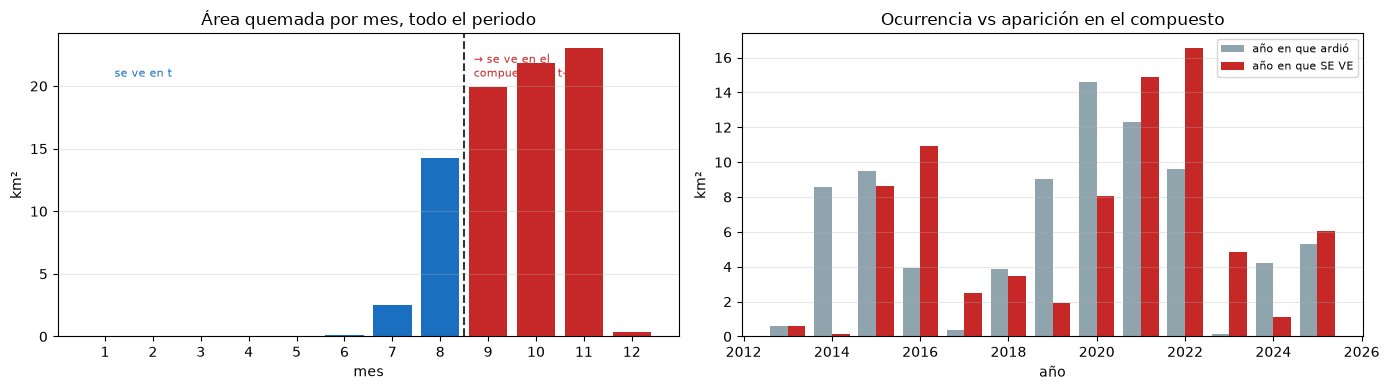

Quemas posteriores a la ventana (mes > 8): 65.18 km² de 82.06 (79.4 %)
Ese porcentaje es el que se perdería si se cruzara por año de ocurrencia.

Los cinco meses de mayor quema:


,,km2,anio_aparicion
anio,mes,,
2020,11,14.2795,2021
2021,10,10.0936,2022
2015,10,8.3402,2016
2019,9,7.2599,2020
2022,8,4.4975,2022


In [17]:
if len(mensual):
    fig, ejes = plt.subplots(1, 2, figsize=(14, 4))

    # Estacionalidad: la razón de ser de este notebook
    por_mes = mensual.groupby("mes")["km2"].sum().reindex(range(1, 13), fill_value=0)
    colores = ["#1a6fc0" if m <= MES_CIERRE_VENTANA else "#c62828" for m in por_mes.index]
    ejes[0].bar(por_mes.index, por_mes.values, color=colores)
    ejes[0].axvline(MES_CIERRE_VENTANA + 0.5, color="#333", ls="--", lw=1.5)
    ejes[0].set_title("Área quemada por mes, todo el periodo")
    ejes[0].set_xlabel("mes")
    ejes[0].set_ylabel("km²")
    ejes[0].set_xticks(range(1, 13))
    ejes[0].text(MES_CIERRE_VENTANA + 0.7, por_mes.max() * 0.9,
                 "→ se ve en el\ncompuesto de t+1", fontsize=8, color="#c62828")
    ejes[0].text(1.2, por_mes.max() * 0.9, "se ve en t", fontsize=8, color="#1a6fc0")

    # Por año de ocurrencia vs por año de aparición
    occ = mensual.groupby("anio")["km2"].sum().reindex(ANIOS, fill_value=0)
    apa = mensual.groupby("anio_aparicion")["km2"].sum().reindex(ANIOS, fill_value=0)
    ancho = 0.4
    ejes[1].bar([a - ancho / 2 for a in ANIOS], occ.values, ancho,
                color="#90a4ae", label="año en que ardió")
    ejes[1].bar([a + ancho / 2 for a in ANIOS], apa.values, ancho,
                color="#c62828", label="año en que SE VE")
    ejes[1].set_title("Ocurrencia vs aparición en el compuesto")
    ejes[1].set_xlabel("año")
    ejes[1].set_ylabel("km²")
    ejes[1].legend(fontsize=8)

    for e in ejes:
        e.grid(alpha=0.3, axis="y")
    plt.tight_layout()
    plt.show()

    post = mensual[~mensual["dentro_ventana"]]["km2"].sum()
    total = mensual["km2"].sum()
    print(f"Quemas posteriores a la ventana (mes > {MES_CIERRE_VENTANA}): "
          f"{post:.2f} km² de {total:.2f} ({post / total * 100:.1f} %)")
    print("Ese porcentaje es el que se perdería si se cruzara por año de ocurrencia.")
    print("\nLos cinco meses de mayor quema:")
    display(mensual.nlargest(5, "km2")[["anio", "mes", "km2", "anio_aparicion"]]
            .set_index(["anio", "mes"]))

## 5 · Las máscaras por año de aparición

El producto de este notebook. Para cada año del periodo, qué píxeles van a mostrar cicatriz de quema
en el compuesto de **ese** año:

```
quema_visible_en(Y)  =  (ardió en Y   con mes ≤ 8)       ← el fuego cayó dentro o antes de la ventana
                     ∨  (ardió en Y-1 con mes ≥ 9)       ← la ventana de Y-1 ya había cerrado
```

Esta es toda la lógica del desfase, y queda resuelta aquí para que el notebook 07 no tenga que
razonar sobre calendarios: pide la banda del año y ya viene alineada.

Dos detalles a tener en cuenta:

- **El primer año de la serie queda incompleto.** Para saber qué se ve en 2013 haría falta saber qué
  ardió en el último trimestre de 2012. Si el producto tiene banda de 2012 se usa; si no, 2013 queda
  subestimado y hay que declararlo.
- **Si el valor no resultara ser el mes** (verificación de la sección 3), se cae a una máscara sin
  desfase y el notebook lo advierte. En ese caso el cruce del notebook 07 tiene que hacerse con
  tolerancia de ±1 año, que es menos preciso.

In [18]:
def quema_mes(anio, mes_min=None, mes_max=None):
    """Máscara de píxeles quemados en un año, opcionalmente filtrando por rango de mes."""
    if anio not in anios_banda:
        return ee.Image(0).rename("q")
    b = fuego.select(anios_banda[anio]).unmask(0)
    m = b.gte(1)                                   # 0 = no ardió
    if VALOR_ES_MES:
        if mes_min is not None:
            m = m.And(b.gte(mes_min))
        if mes_max is not None:
            m = m.And(b.lte(mes_max))
    return m.rename("q")


def quema_visible_en(anio):
    """Píxeles con cicatriz visible en el compuesto de 'anio', resolviendo el desfase."""
    if not VALOR_ES_MES:
        # Sin interpretación del mes no se puede desfasar: se devuelve la quema del año
        return quema_mes(anio).rename(f"q{anio}")
    dentro = quema_mes(anio, mes_max=MES_CIERRE_VENTANA)          # ardió en t, mes <= 8
    arrastre = quema_mes(anio - 1, mes_min=MES_CIERRE_VENTANA + 1)  # ardió en t-1, mes >= 9
    return dentro.Or(arrastre).rename(f"q{anio}")


QUEMA_APARICION = ee.Image.cat([quema_visible_en(a) for a in ANIOS]).toByte().set({
    "descripcion": "1 = cicatriz de quema visible en el compuesto de ese año",
    "desfase": f"mes<={MES_CIERRE_VENTANA} -> ano t ; mes>={MES_CIERRE_VENTANA + 1} -> ano t+1",
    "valor_es_mes": "si" if VALOR_ES_MES else "NO (sin desfase aplicado)",
    "fuente": ASSET_FUEGO.split("/")[-1],
    "notebook": "03_referencia_fuego",
})

print("Bandas de la máscara de aparición:",
      con_reintentos(lambda: QUEMA_APARICION.bandNames().getInfo()))

if (ANIO_INI - 1) not in anios_banda:
    print(f"\n⚠ No hay banda de fuego para {ANIO_INI - 1}, así que el año {ANIO_INI} no puede")
    print(f"  incluir el arrastre del último trimestre de {ANIO_INI - 1}: queda subestimado.")
    print("  Declararlo como limitación en el informe.")

if not VALOR_ES_MES:
    print("\n⚠ El valor del píxel no resultó ser el mes: la máscara NO lleva desfase aplicado.")
    print("  El notebook 07 debe cruzar con tolerancia de ±1 año, sesgada hacia t+1.")

Bandas de la máscara de aparición: ['q2013', 'q2014', 'q2015', 'q2016', 'q2017', 'q2018', 'q2019', 'q2020', 'q2021', 'q2022', 'q2023', 'q2024', 'q2025']


## 6 · Cuánto de la quema cae sobre pajonal

El dato que decide si el fuego es un confusor relevante para **este** indicador. El fuego sobre
cultivos o sobre matorral no interfiere: lo que importa es cuánto arde dentro de la máscara de
pajonal, que es la población donde medimos degradación.

In [19]:
def km2_de(mascara):
    v = (ee.Image.pixelArea().divide(1e6).updateMask(mascara)
         .reduceRegion(ee.Reducer.sum(), aoi, ESCALA_STATS,
                       maxPixels=1e10, bestEffort=True, tileScale=TILE_SCALE))
    return ee.Number(v.get("area"))


if HAY_MASCARA and len(mensual):
    # Quema acumulada en todo el periodo, con y sin pajonal
    quema_total = QUEMA_APARICION.reduce(ee.Reducer.max()).selfMask()

    print("Superficie quemada alguna vez en el periodo:")
    vals = evaluar_serie(
        [km2_de(quema_total), km2_de(quema_total.updateMask(pastizal))],
        ["en la provincia", "dentro del pajonal"])

    print(f"\n  En la provincia       : {vals[0]:7.2f} km²")
    print(f"  Dentro del pajonal    : {vals[1]:7.2f} km²  "
          f"({vals[1] / vals[0] * 100:.1f} % de lo quemado)")

    # Por año de aparición, solo sobre pajonal: lo que el notebook 07 va a tener que descontar
    print("\nQuema sobre pajonal por año de aparición:")
    por_anio = evaluar_serie(
        [km2_de(QUEMA_APARICION.select(f"q{a}").selfMask().updateMask(pastizal)) for a in ANIOS],
        [str(a) for a in ANIOS])

    quema_pajonal = pd.DataFrame({
        "anio_aparicion": ANIOS,
        "km2_quemado_en_pajonal": [round(v or 0, 4) for v in por_anio],
    })
    quema_pajonal.to_csv(SALIDA / "quema_en_pajonal_por_anio.csv", index=False)
    display(quema_pajonal.set_index("anio_aparicion").T)
    print("Guardado en", SALIDA / "quema_en_pajonal_por_anio.csv")
else:
    print("Sin máscara de pajonal (o sin quema registrada): sección omitida.")
    print("Ejecuta el notebook 02 y su celda de exportación para habilitarla.")
    quema_pajonal = pd.DataFrame(columns=["anio_aparicion", "km2_quemado_en_pajonal"])

Superficie quemada alguna vez en el periodo:
  [1/2] en la provincia  

ok
  [2/2] dentro del pajonal  ok

  En la provincia       :   68.34 km²
  Dentro del pajonal    :   52.11 km²  (76.3 % de lo quemado)

Quema sobre pajonal por año de aparición:
  [1/13] 2013  ok
  [2/13] 2014  ok
  [3/13] 2015  ok
  [4/13] 2016  ok
  [5/13] 2017  ok
  [6/13] 2018  ok
  [7/13] 2019  ok
  [8/13] 2020  ok
  [9/13] 2021  ok
  [10/13] 2022  ok
  [11/13] 2023  ok
  [12/13] 2024  ok
  [13/13] 2025  ok


anio_aparicion,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
km2_quemado_en_pajonal,0.9713,0.0765,6.4549,7.3841,1.6248,3.2274,1.4994,6.7753,10.8703,12.4507,3.8845,1.055,5.4542


Guardado en F:\Cobertura de suelo\outputs\03_referencia_fuego\quema_en_pajonal_por_anio.csv


## 7 · Control visual

Dónde se concentran las quemas. Sirve para ver si están donde tiene sentido —laderas, zonas de
pastoreo— o si hay artefactos evidentes.

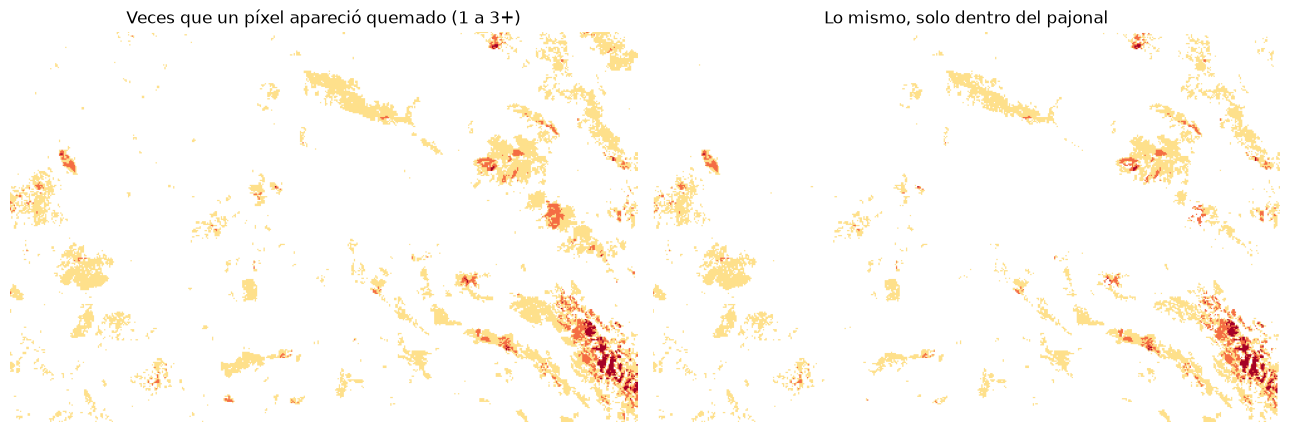

La recurrencia importa: un píxel que arde repetidamente puede mostrar una
trayectoria descendente sostenida y parecerse a degradación gradual.


In [20]:
def miniatura(img, vis, ancho=500):
    from PIL import Image
    import requests, io
    url = img.getThumbURL({**vis, "region": aoi, "dimensions": ancho, "format": "png"})
    return np.array(Image.open(io.BytesIO(requests.get(url, timeout=240).content)))


if len(mensual):
    # Número de años en que cada píxel apareció quemado: la recurrencia
    recurrencia = QUEMA_APARICION.reduce(ee.Reducer.sum()).selfMask()

    fig, ejes = plt.subplots(1, 2, figsize=(13, 6))
    ejes[0].imshow(miniatura(recurrencia, {
        "min": 1, "max": 3, "palette": ["#fee08b", "#f46d43", "#a50026"]}))
    ejes[0].set_title("Veces que un píxel apareció quemado (1 a 3+)")

    if HAY_MASCARA:
        ejes[1].imshow(miniatura(recurrencia.updateMask(pastizal), {
            "min": 1, "max": 3, "palette": ["#fee08b", "#f46d43", "#a50026"]}))
        ejes[1].set_title("Lo mismo, solo dentro del pajonal")
    else:
        ejes[1].axis("off")

    for e in ejes:
        e.axis("off")
    plt.tight_layout()
    plt.show()
    print("La recurrencia importa: un píxel que arde repetidamente puede mostrar una")
    print("trayectoria descendente sostenida y parecerse a degradación gradual.")

## 8 · Exportar

La máscara por año de aparición va a un asset: es lo que consume el notebook 07, y tenerla
precalculada evita que ese notebook vuelva a resolver el desfase.

In [ ]:
EXPORTAR_ASSET = False      # ponlo en True una sola vez

if EXPORTAR_ASSET and len(mensual):
    tarea = ee.batch.Export.image.toAsset(
        image=QUEMA_APARICION, description="cusco_03_quema_aparicion", assetId=ASSET_QUEMA,
        region=aoi, scale=ESCALA, crs=GRID_CRS, maxPixels=1e10,
        pyramidingPolicy={".default": "mode"})      # máscaras binarias: mode, no mean
    tarea.start()
    print("Tarea lanzada:", tarea.id, "→", ASSET_QUEMA)
    print("Seguimiento: pestaña Tasks del Code Editor, o ee.batch.Task.list()")
else:
    print("EXPORTAR_ASSET = False.")
    print("Ponlo en True y ejecuta esta celda UNA VEZ para crear", ASSET_QUEMA)
    print(f"Contendría {len(ANIOS)} bandas (q{ANIO_INI} a q{ANIO_FIN}).")

Tarea lanzada: 4RZH4N7YZ2CCGZEBOIKSMQ53 → projects/viirs-peru/assets/cusco_03_quema_aparicion
Seguimiento: pestaña Tasks del Code Editor, o ee.batch.Task.list()


## 9 · Resumen

In [22]:
print("=" * 76)
print("RESUMEN · notebook 03 · MapBiomas Fuego")
print("=" * 76)
print("Producto   :", ASSET_FUEGO.split("/")[-1])
print("Tipo       :", TIPO_FUEGO, "| mensual:", MENSUAL, "| el valor es el mes:", VALOR_ES_MES)
print("Periodo    :", f"{anios_con_dato[0]}–{anios_con_dato[-1]}" if anios_con_dato else "sin datos")
print()
if len(mensual):
    post = mensual[~mensual["dentro_ventana"]]["km2"].sum()
    total = mensual["km2"].sum()
    print(f"Área quemada acumulada        : {total:7.2f} km²")
    print(f"Meses con quema registrada    : {len(mensual)}")
    print(f"Posterior a la ventana (>{MES_CIERRE_VENTANA})   : {post:7.2f} km²  "
          f"({post / total * 100:.1f} %) → se ve un año después")
    if len(quema_pajonal):
        print(f"Quema sobre pajonal (acumul.) : "
              f"{quema_pajonal['km2_quemado_en_pajonal'].sum():7.2f} km²")
    print()
    print("Años de mayor quema:")
    for _, f in anual.nlargest(3, "km2_quemado").iterrows():
        print(f"  {int(f['anio'])}: {f['km2_quemado']:.2f} km²")
print()
print("ARCHIVOS GENERADOS")
for n in ["area_quemada_mensual.csv", "area_quemada_anual.csv", "quema_en_pajonal_por_anio.csv"]:
    r = SALIDA / n
    print(f"  {'✓' if r.exists() else '·'} {r}")
print(f"  {'·'} asset {ASSET_QUEMA}  (requiere EXPORTAR_ASSET = True)")
print()
print("-" * 76)
print("LIMITACIONES A DECLARAR")
print("-" * 76)
print("· La codificación del mes no está confirmada contra la documentación oficial de")
print("  MapBiomas Fuego. Los totales anuales no dependen de esa interpretación; la")
print("  asignación mensual sí, y se presenta como provisional.")
print(f"· El año {ANIO_INI} queda subestimado si no hay banda de {ANIO_INI - 1}: le falta el")
print(f"  arrastre de las quemas del último trimestre de {ANIO_INI - 1}.")
print("· El producto de fuego tiene su propia exactitud, no verificada aquí. Una quema")
print("  no detectada por MapBiomas se contará como degradación en el notebook 07.")
print()
print("SIGUIENTE · notebook 07 · tipo de cambio")
print("  Lee la banda qYYYY del asset y la cruza con el año de quiebre de LandTrendr.")
print("  El desfase ya viene resuelto: no hay que volver a razonar sobre calendarios.")
print("=" * 76)

RESUMEN · notebook 03 · MapBiomas Fuego
Producto   : mapbiomas_peru_fire_collection2_monthly_burned_v1
Tipo       : IMAGE | mensual: True | el valor es el mes: True
Periodo    : 2013–2025

Área quemada acumulada        :   82.06 km²
Meses con quema registrada    : 71
Posterior a la ventana (>8)   :   65.18 km²  (79.4 %) → se ve un año después
Quema sobre pajonal (acumul.) :   61.73 km²

Años de mayor quema:
  2020: 14.58 km²
  2021: 12.32 km²
  2022: 9.63 km²

ARCHIVOS GENERADOS
  ✓ F:\Cobertura de suelo\outputs\03_referencia_fuego\area_quemada_mensual.csv
  ✓ F:\Cobertura de suelo\outputs\03_referencia_fuego\area_quemada_anual.csv
  ✓ F:\Cobertura de suelo\outputs\03_referencia_fuego\quema_en_pajonal_por_anio.csv
  · asset projects/viirs-peru/assets/cusco_03_quema_aparicion  (requiere EXPORTAR_ASSET = True)

----------------------------------------------------------------------------
LIMITACIONES A DECLARAR
----------------------------------------------------------------------------
·